# Filbin et al. 2018 — Pediatric H3-K27M Mutant Glioma (SmartSeq2)
## 01 · Preprocessing

Load malignant cells, derive the per-sample threshold from the data, integrate samples with
Harmony, embed, remove detached islands, and settle each sub-region's biology (signatures +
cell cycle) **before** the Gate-1 call. H3-K27M glioma is the textbook glial developmental
hierarchy (Filbin *et al.*, *Science* 2018): a cycling **OPC-like** progenitor that
differentiates into **OC-like** (oligodendrocytic) and **AC-like** (astrocytic) states — a
genuinely branching manifold.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths: cwd = <root>/mesencontext/claude/<Category>/<Dataset>-4  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Filbin2018_Brain-4
stem = name[:-2] if name.endswith('-4') else name       # dataset folder minus the -4 suffix
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Brain
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + stem)                       # raw input (flat leaf)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', stem, '| category:', cat)

dataset: Filbin2018_Brain | category: Brain


### Load malignant cells
Flat leaf directory (single `Exp_data_TPM.mtx`; TPM passes through, `log1p` only). Keep
`Malignant` cells; carry Filbin's published per-cell annotations (`opc_like`/`oc_like`/`ac_like`
developmental scores, `cell_cycle_phase`, meta-programs) as `obs` for the biology-before-geometry
checks below.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
print('all cell types:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
for c in ['oc_like','ac_like','opc_like','g1s_score','g2m_score','complexity','mp_top_score']:
    if c in adata.obs: adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
adata.obs['cyc_score'] = adata.obs[['g1s_score','g2m_score']].max(axis=1)
adata.obs['cyc'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('malignant:', adata.shape, '| TPM log1p, X max %.2f' % adata.X.max())
CELLS_MALIGNANT_RAW = adata.shape[0]

all cell types: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | TPM log1p, X max 12.36


### Per-sample threshold — derived, not inherited (C1)
Sort per-sample malignant counts and look for a clean gap (the rule's premise, C3). SmartSeq2
plate counts here are **smooth** (largest adjacent ratio well under 2x), so there is no gap to
cut on; fall back to the >=100-cell floor. With only 6 patients a geometric-mean cut would drop
the smallest patient on a weak ratio — over-aggressive. Assumption stated and checked in code.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample malignant counts:'); print(n.to_string())
print(f'largest adjacent ratio: {int(vals[gap])} -> {int(vals[gap+1])} = {ratios[gap]:.2f}x')
FLOOR = 100
if ratios[gap] >= 2.0:
    thr = int(np.sqrt(vals[gap]*vals[gap+1])); print(f'clean gap present -> geometric-mean threshold = {thr}')
else:
    thr = FLOOR; print(f'no clean gap (max ratio {ratios[gap]:.2f} < 2.0) -> floor threshold = {thr}')
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
CELLS_AFTER_THRESHOLD = adata.shape[0]

sorted per-sample malignant counts:
sample
MUV05      667
BCH869     489
BCH836     438
MUV10      283
BCH1126    241
MUV01      141
largest adjacent ratio: 241 -> 141 = 1.71x
no clean gap (max ratio 1.71 < 2.0) -> floor threshold = 100
kept 6/6 samples -> 2259 cells


### Gene filtering + overdispersed selection + PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
N_OD = int(adata.var.highly_variable.sum())
print('overdispersed genes:', N_OD)
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3779 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3779


### Harmony integration — iLISI sweep on `sample` (Gate-1 evidence, C2)
Per-neighborhood iLISI (ideal = number of samples) across an integration-strength sweep, never a
single scalar. Mixing rises then plateaus; pick the strongest theta before saturation.

In [6]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: iLISI %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s)))
THETA = 10
print('selected theta =', THETA, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=30, random_state=SEED)

sample iLISI (ideal 6); pre-Harmony PCA: 1.23
2026-08-08 01:10:55,244 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 01:10:55,646 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 01:10:55,654 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 01:10:56,012 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 01:10:56,378 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 01:10:56,734 - harmonypy - INFO - Iteration 4 of 30
2026-08-08 01:10:57,091 - harmonypy - INFO - Converged after 4 iterations
  theta= 1: iLISI 3.00
2026-08-08 01:10:57,224 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 01:10:57,571 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 01:10:57,578 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 01:10:57,933 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 01:10:58,293 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 01:10:58,660 - harmonypy - INFO - Iteration

### Neighbors -> UMAP -> island removal
`n_pcs=20` (SmartSeq2 scale, matching the Brain precedents), `spread=1.3`. Remove genuinely
detached islands via a UMAP radius graph (6x median NN distance), keep the largest component,
then rebuild the graph on retained cells so the manifold is one clean connected piece.

In [7]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands: removed', int((lab != main).sum()), 'cells in', ncomp-1, 'components')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
CELLS_AFTER_ISLAND = adata.shape[0]
print('retained one connected component:', CELLS_AFTER_ISLAND, 'cells')

detached islands: removed 0 cells in 0 components
retained one connected component: 2259 cells


### Subtype annotation — data-derived + publication (both, per spec)
Filbin *et al.* 2018 (*Science* 360:331) describe H3-K27M glioma as a developmental hierarchy: a
cycling **OPC-like** progenitor compartment that differentiates into **OC-like** (oligodendrocytic)
and **AC-like** (astrocytic) states. We annotate from the publication's own per-cell developmental
scores (`opc_like`/`oc_like`/`ac_like`) — dominant program per cell — and separate the cycling
OPC-like progenitors (`Cycling-OPC`), which are proliferation-confounded and must be scoped out of
the Gate-3 hub (the binding Kürten-fork lesson).

In [8]:
sc.tl.leiden(adata, resolution=0.4, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
sub = adata.obs[['opc_like','oc_like','ac_like']].copy()
dom = sub.idxmax(axis=1).map({'opc_like':'OPC-like','oc_like':'OC-like','ac_like':'AC-like'})
dom[(adata.obs['cyc']) & (dom == 'OPC-like')] = 'Cycling-OPC'
adata.obs['celltype'] = pd.Categorical(dom, categories=['Cycling-OPC','OPC-like','OC-like','AC-like'])
print('subtype composition:'); print(adata.obs['celltype'].value_counts().to_string())
SUBTYPES = ','.join([c for c in adata.obs['celltype'].cat.categories if (adata.obs['celltype']==c).any()])

subtype composition:
celltype
OPC-like       994
OC-like        611
AC-like        449
Cycling-OPC    205


6 samples on one continuous manifold; sample iLISI = 3.77 of 6
GATE 1: samples intermixed (iLISI well above 1) on a single connected manifold, no detached islands -> mixed AND continuous -> GO


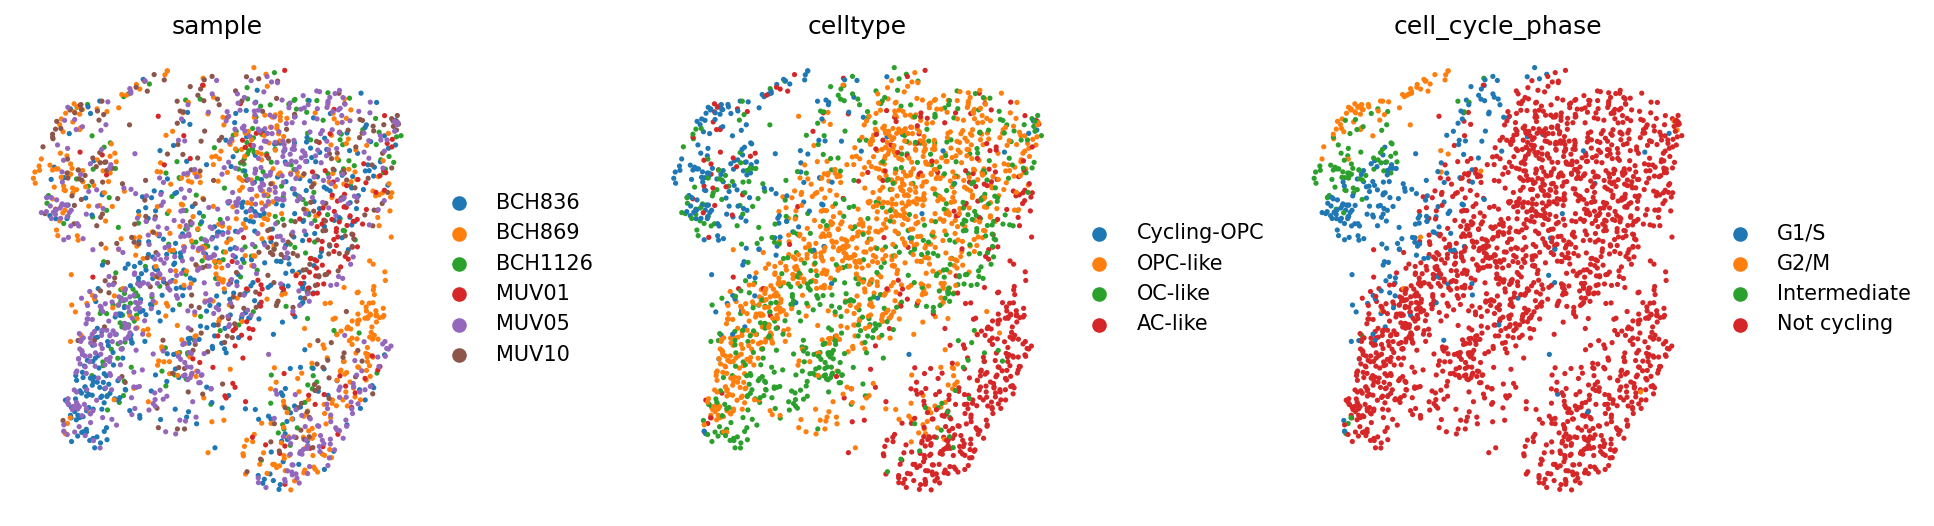

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'celltype', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=25, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
print(f'{nsamp} samples on one continuous manifold; '
      f'sample iLISI = {ilisi(adata.obsm["X_pca_harmony"][:,:20], adata.obs["sample"].values):.2f} of {nsamp}')
print('GATE 1: samples intermixed (iLISI well above 1) on a single connected manifold,',
      'no detached islands -> mixed AND continuous -> GO')

### Save processed data

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)
print(f'counts: raw_malignant={CELLS_MALIGNANT_RAW} after_threshold={CELLS_AFTER_THRESHOLD} '
      f'after_island={CELLS_AFTER_ISLAND}')

saved processed.h5ad (2259, 21224)
counts: raw_malignant=2259 after_threshold=2259 after_island=2259


### Deliverable — `samples.pdf`
Single sample-coloured manifold UMAP (reference style).

saved samples.pdf | cells: 2259


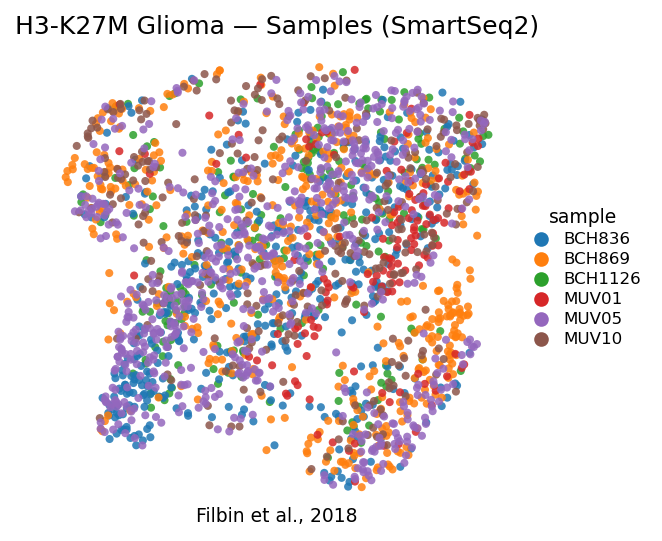

In [11]:
# branching manifold -> square panel (Puram branching reference aspect), consistent orientation
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(adata, color='sample', size=60, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.0, .5),
          handletextpad=.3, labelspacing=.3, fontsize=8, title='sample', title_fontsize=9)
ax.set_title('H3-K27M Glioma — Samples (SmartSeq2)', size=12)
ax.text(.5, -.03, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=9)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', adata.shape[0])